In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set Matplotlib defaults
plt.style.use("seaborn-v0_8-whitegrid")
plt.rc("figure", autolayout=True)
plt.rc(
    "axes",
    labelweight="bold",
    labelsize="large",
    titleweight="bold",
    titlesize=14,
    titlepad=10,
)

ames_data = pd.read_csv("../datasets/fe-course-data/ames.csv")

In [2]:
from category_encoders import MEstimateEncoder
from sklearn.model_selection import cross_val_score
from xgboost import XGBRegressor

def score_dataset(X, y, model=XGBRegressor()):
    # Label encoding for categoricals
    for colname in X.select_dtypes(["category", "object"]):
        X[colname], _ = X[colname].factorize()
    # Metric for Housing competition is RMSLE (Root Mean Squared Log Error)
    score = cross_val_score(
        model, X, y, cv=5, scoring="neg_mean_squared_log_error",
    )
    score = -1 * score.mean()
    score = np.sqrt(score)
    return score

In [3]:
ames_data.select_dtypes(["object"]).nunique().sort_values(ascending=False)

Neighborhood     28
Exterior2nd      17
Exterior1st      16
MSSubClass       16
SaleType         10
OverallQual      10
Condition1        9
OverallCond       9
RoofMatl          8
Functional        8
HouseStyle        8
Condition2        8
BsmtFinType2      7
MSZoning          7
BsmtFinType1      7
GarageType        7
GarageQual        6
FireplaceQu       6
Electrical        6
BsmtCond          6
Foundation        6
RoofStyle         6
GarageCond        6
SaleCondition     6
Heating           6
BsmtQual          6
MiscFeature       5
PoolQC            5
BldgType          5
LotConfig         5
Fence             5
HeatingQC         5
KitchenQual       5
ExterCond         5
BsmtExposure      5
LotShape          4
LandContour       4
ExterQual         4
MasVnrType        4
GarageFinish      4
Alley             3
LandSlope         3
PavedDrive        3
Utilities         3
Street            2
CentralAir        2
dtype: int64

In [4]:
ames_data["Neighborhood"].value_counts()

Neighborhood
North_Ames                                 443
College_Creek                              267
Old_Town                                   239
Edwards                                    194
Somerset                                   182
Northridge_Heights                         166
Gilbert                                    165
Sawyer                                     151
Northwest_Ames                             131
Sawyer_West                                125
Mitchell                                   114
Brookside                                  108
Crawford                                   103
Iowa_DOT_and_Rail_Road                      93
Timberland                                  72
Northridge                                  71
Stone_Brook                                 51
South_and_West_of_Iowa_State_University     48
Clear_Creek                                 44
Meadow_Village                              37
Briardale                                   30


In [5]:
ames_data["SaleType"].value_counts()

SaleType
WD       2536
New       239
COD        87
ConLD      26
CWD        12
ConLI       9
ConLw       8
Oth         7
Con         5
VWD         1
Name: count, dtype: int64

In [6]:
from IPython.display import display, Markdown

content = f"""
**Q**: **Which features did you identify for target encoding?**<br>
**A**: The `Neighborhood` feature looks promising. It has the most categories of any feature, 
and several categories are rare. Others that could be worth considering are `SaleType`, `MSSubClass`, 
`Exterior1st`, and `Exterior2nd`. In fact, almost any of the nominal features would be worth trying because 
of the prevalence of rare categories.
"""

display(Markdown(content))


**Q**: **Which features did you identify for target encoding?**<br>
**A**: The `Neighborhood` feature looks promising. It has the most categories of any feature, 
and several categories are rare. Others that could be worth considering are `SaleType`, `MSSubClass`, 
`Exterior1st`, and `Exterior2nd`. In fact, almost any of the nominal features would be worth trying because 
of the prevalence of rare categories.


In [7]:
# Encoding split
X_encode = ames_data.sample(frac=0.20, random_state=0)
y_encode = X_encode.pop("SalePrice")

# Training split
X_pretrain = ames_data.drop(X_encode.index)
y_train = X_pretrain.pop("SalePrice")

In [8]:
# Choose a set of features to encode and a value for m
encoder = MEstimateEncoder(cols=["Neighborhood"], m=5.0)


# Fit the encoder on the encoding split
encoder.fit(X_encode, y_encode)

# Encode the training split
X_train = encoder.transform(X_pretrain, y_train)

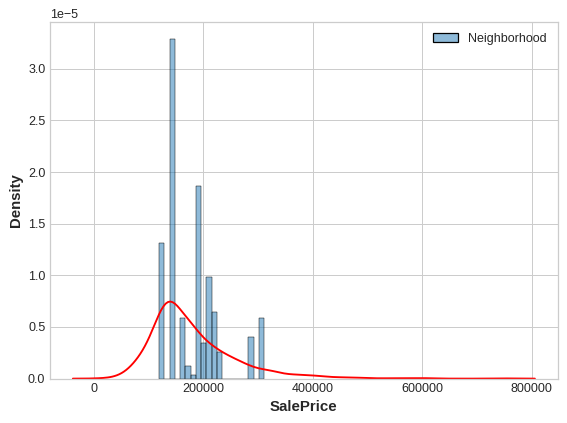

In [42]:
feature = encoder.cols

plt.figure(dpi=90)
ax = sns.kdeplot(y_train, color='r')
ax = sns.histplot(X_train[feature], ax=ax, kde=False, stat="density")

ax.set_xlabel("SalePrice");

In [44]:
X = ames_data.copy()
y = X.pop("SalePrice")
score_base = score_dataset(X, y)
score_new = score_dataset(X_train, y_train)

print(f"Baseline Score: {score_base:.4f} RMSLE")
print(f"Score with Encoding: {score_new:.4f} RMSLE")

Baseline Score: 0.1434 RMSLE
Score with Encoding: 0.1398 RMSLE


In [55]:
# Try experimenting with the smoothing parameter m
for m in [0, 1, 5, 50]:
    X = ames_data.copy()
    y = X.pop('SalePrice')
    
    # Create an uninformative feature
    X["Count"] = range(len(X))
    X.loc[1, "Count"] = 0

    # fit and transform on the same dataset
    encoder = MEstimateEncoder(cols="Count", m=m)
    X = encoder.fit_transform(X, y)

    # Results
    score =  score_dataset(X, y)
    print(f"m:{m}, Score: {score:.4f} RMSLE")

m:0, Score: 0.0375 RMSLE
m:1, Score: 0.0359 RMSLE
m:3, Score: 0.0381 RMSLE
m:5, Score: 0.0355 RMSLE
m:50, Score: 0.0362 RMSLE


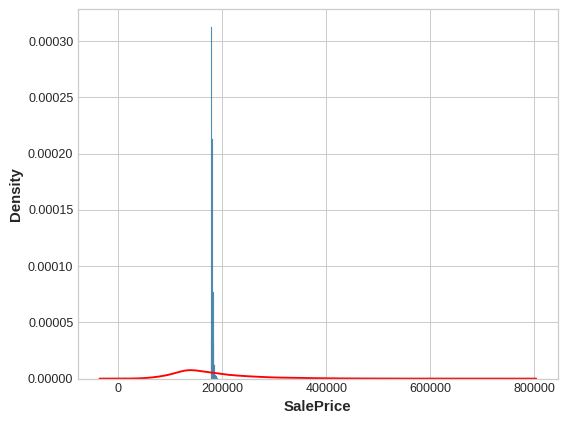

In [69]:
plt.figure(dpi=90)
ax = sns.kdeplot(y, color='red')
ax = sns.histplot(X["Count"], ax=ax, kde=False, stat="density", bins=10)
ax.set_xlabel("SalePrice");